# EN.605.631 — Random Variables with R (Chapter 4)

**Format:** Jupyter Notebook (**R kernel**)  
**Estimated time:** ~5 hours  
**Total points:** 100

This version includes **function stubs** and **plotting scaffolds** to help you structure solutions quickly. Replace `TODO` parts with your code.

## 📝 Setup

At the very top, include:
- `R.version.string` and `sessionInfo()`  
- `set.seed(631)`  
- List any packages you use (base R preferred; `ggplot2`/`dplyr` optional).

> Tip: Use vectorized operations and report Monte Carlo uncertainty where requested.

In [1]:
# --- Required setup (fill in) ---
R.version.string
sessionInfo()
set.seed(631)

# If you choose to use ggplot2 / dplyr:
# suppressPackageStartupMessages({
#   library(ggplot2)
#   library(dplyr)
# })

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

## 🔧 Common utilities (optional)

In [2]:
# Monte Carlo SE for a sample mean
mc_se_mean <- function(x) sd(x)/sqrt(length(x))

# Monte Carlo SE for a Bernoulli proportion
mc_se_prop <- function(p_hat, n) sqrt(p_hat*(1-p_hat)/n)

# 95% CI for a proportion (Wald)
ci95_prop <- function(p_hat, n){
  se <- mc_se_prop(p_hat, n)
  c(lower = max(0, p_hat - 1.96*se),
    upper = min(1, p_hat + 1.96*se))
}

# Safe factorial / combinations via lgamma
lfact <- function(n) lgamma(n + 1)
nCr_lgamma <- function(n, r) {
  if (r < 0 || r > n) return(0)
  round(exp(lfact(n) - lfact(r) - lfact(n-r)))
}

---
## Problem 1 — Discrete RV: pmf, cdf, plots, and checks (10 pts)

Let $X$ be the number of heads in 4 independent flips of a coin with $P(H)=0.6$.

1. **(5 pts)** Derive the pmf of $X$ and its cdf; show the cdf is a right-continuous step function. Plot both pmf and cdf.  
2. **(5 pts)** Compute $E[X]$ and $\mathrm{Var}(X)$ two ways: (i) binomial formulas; (ii) indicator-sum argument. Verify numerically in R by exact probabilities.

### PMF

$X \sim \mathrm{Binomial}(4,0.6)$

$X$ is binomial because there are $n=4$ independent flips with probability $p=0.6$

The PMF is $P(X=k)=\binom{4}{k}(0.6)^k(0.4)^{4-k},\text{  }k=0,1,2,3,4$

In [3]:
# (A) PMF generator for Binomial(n, p)
pmf_binomial <- function(n, p){
  # TODO: return a data.frame with columns: k (0:n) and pmf (P[X=k])
  # hint: dbinom
  k <- 0:n
  pmf <- dbinom(k, n, p)
  data.frame(k=k, pmf=pmf)
}

### CDF

The CDF is $F(x)=P(X\leq x)$

The CDF is strictly non-decresasing for all $x$. To the right of any $x$, the CDF remains $F(x)$. $\lim_{x\to a^+}F(x)=F(a),$
and the same property holds for all $a$, meaning CDF is a right-continuous step function.

k,pmf
<int>,<dbl>
0,0.0256
1,0.1536
2,0.3456
3,0.3456
4,0.1296


k,cdf
<int>,<dbl>
0,0.0256
1,0.1792
2,0.5248
3,0.8704
4,1.0000


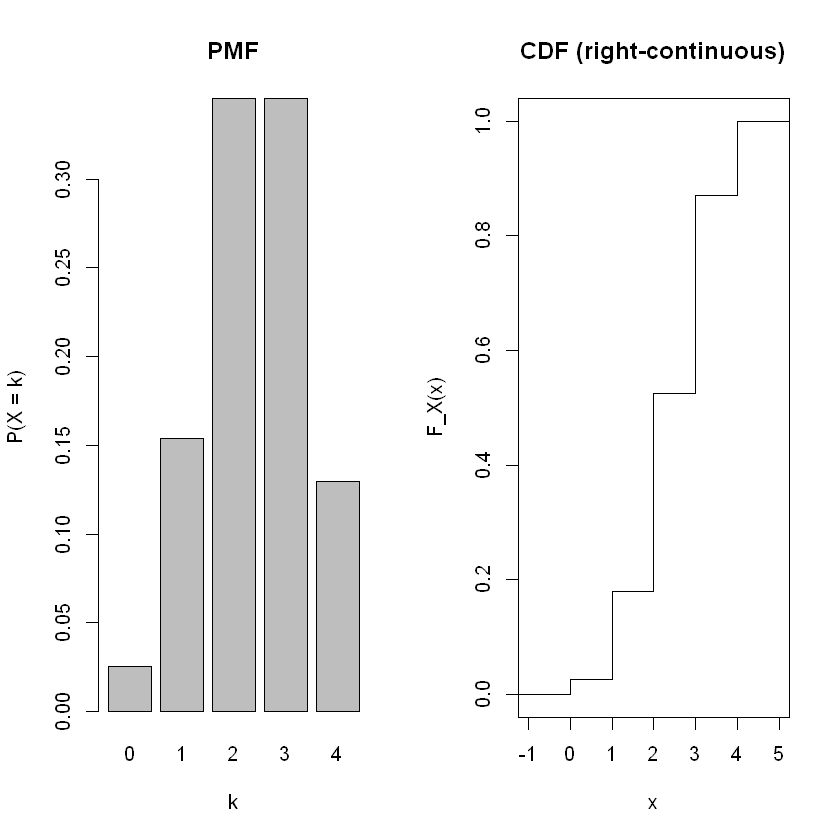

In [4]:
# (B) CDF from a PMF
cdf_from_pmf <- function(pmf_df){
  # pmf_df: data.frame with k and pmf
  # returns data.frame with k and cdf (right-continuous steps)
  cdf <- cumsum(pmf_df$pmf)  # OK once pmf filled
  data.frame(k = pmf_df$k, cdf = cdf)
}

# (C) Plotting scaffold (base R)
plot_pmf_cdf <- function(pmf_df){
  cdf_df <- cdf_from_pmf(pmf_df)
  op <- par(mfrow=c(1,2))
  on.exit(par(op), add=TRUE)
  # PMF barplot
  barplot(height = pmf_df$pmf, names.arg = pmf_df$k,
          main = "PMF", xlab = "k", ylab = "P(X = k)")
  # CDF step plot
  plot(stepfun(cdf_df$k, c(0, cdf_df$cdf)),
       do.points=FALSE, pch=16, main="CDF (right-continuous)",
       xlab="x", ylab="F_X(x)")
}

pmf <- pmf_binomial(4, 0.6)
pmf
cdf <- cdf_from_pmf(pmf)
cdf
plot_pmf_cdf(pmf)

### Binomial Formulas

$E[X]=np$

$\mathrm{Var}(X)=np(1-p)$

For $n=4$ and $p=0.6$,

$E[X]=4(0.6)=2.4$

$\mathrm{Var}(X)=4(0.6)(0.4)=0.96$

### Indicator Variable

$I_i=\{1\text{ if flip }i\text{ is a head},0 \text{ if flip }i\text{ is a tail}\}$

$X=\sum_{i=1}^4 I_i$

$E[I_i]=p$

$\mathrm{Var}(I_i)=p(1-p)$

$E[X]=E\left[\sum_{i=1}^n I_i\right]=\sum_{i=1}^n E[I_i]=np$

$\mathrm{Var}(X)=\mathrm{Var}\left(\sum_{i=1}^n I_i\right)=\sum_{i=1}^n \mathrm{Var}(I_i)=\sum_{i=1}^n p(1-p)=np(1-p)$

In [5]:
# (D) Indicator-sum E and Var scaffold
binom_indicator_moments <- function(n, p){
  # TODO: Using X = sum_{i=1}^n I_i where I_i ~ Bernoulli(p) independent,
  # derive E[X] and Var(X) and return as list(E=..., Var=...)
  E <- n * p
  Var <- n * p * (1-p) 
  list(E = E, Var = Var)
}

moms <- binom_indicator_moments(n=4, p=0.6); moms

$E
[1] 2.4

$Var
[1] 0.96

In [6]:
E <- sum(pmf$k * pmf$pmf)
EX2 <- sum((pmf$k^2) * pmf$pmf)
Var <- EX2 - E^2

E
Var

[1] 2.4

[1] 0.96

---
## Problem 2 — LOTUS and transformations (12 pts)

Let $X\sim\text{Binomial}(n=10,p=0.3)$. Define $g(x)=x^2+3x+1$.

1. **(8 pts)** Using LOTUS, compute $E[g(X)]$ from the pmf and compare to a simulation of $10^6$ draws (report MC standard error).  
2. **(4 pts)** Show and verify $E[aX+b]=aE[X]+b$ with $a=-2, b=5$; confirm numerically.

### LOTUS

By Proposition 4.1, $E[g(X)] = \sum_x g(x)P(X=x)$

A binomial random variable can take values $0,1,\ldots,10$

$E[g(X)] = \sum_{k=0}^{10} (k^2+3k+1)P(X=k)$ where $P(X=k)=\binom{10}{k}(0.3)^k(0.7)^{10-k}$

$E[X]=np=10(0.3)=3$

$\mathrm{Var}(X)=np(1-p)=10(0.3)(0.7)=2.1$

$E[X^2]=\mathrm{Var}(X)+(E[X])^2=2.1+3^2=11.1$

$E[g(X)] = E[X^2+3X+1]$

$=E[X^2]+3E[X]+1$

$=11.1+3(3)+1$

$=21.1$

In [7]:
g_fun <- function(x){ x^2 + 3*x + 1 }

E_by_LOTUS_binom <- function(n, p, g = g_fun){
  # TODO: compute E[g(X)] where X ~ Bin(n,p)
  # hint: sum over k=0..n of g(k)*dbinom(k, n, p)
  k <- 0:n
  sum(g(k) * dbinom(k, n, p))
}

E_by_LOTUS_binom(10, 0.3)

[1] 21.1

### Simulation

In [8]:
simulate_Eg_binom <- function(n, p, N = 1e6, g = g_fun){
  # TODO: simulate X ~ Bin(n,p), compute mean(g(X)) and MC SE
  # return list(mean_hat=..., se=...)
  x <- rbinom(N, n, p)
  mean_hat <- mean(g(x))
  se <- mc_se_mean(g(x))
  list(mean_hat = mean_hat, se = se)
}

simulate_Eg_binom(10, 0.3, 1000000)

$mean_hat
[1] 21.11101

$se
[1] 0.01390073

### Linearity of Expectation

If $a$ and $b$ are constants then $E[aX+b]=aE[X]+b$

$E[aX+b]=\sum_{x: p(x)>0} (ax+b)p(x)$

$= a\sum_{x: p(x)>0} xp(x)+b\sum_{x: p(x)>0} p(x)$

$=aE[X]+b$

In [9]:
affine_check <- function(n, p, a = -2, b = 5){
  # TODO: Verify E[aX+b] = aE[X] + b empirically and analytically
  # return a small list with both sides
  k <- 0:n
  lhs <- sum((a * k + b) * dbinom(k, n, p))
  rhs <- a * (n * p) + b
  list(lhs = lhs, rhs = rhs)
}

affine_check(10, 0.3, -2, 5)

$lhs
[1] -1

$rhs
[1] -1

For $X\sim\text{Binomial}(n=10,p=0.3)$ with $a=-2$ and $b=5$

$E[X]=10(0.3)=3$

$E[-2X+5]=-2(3)+5=-1$

---
## Problem 3 — Binomial vs Poisson (12 pts)

Consider $Y\sim\text{Binomial}(n=1000,p=0.004)$.

1. **(6 pts)** Use Poisson($\lambda=np$) as an approximation; compute the absolute error in $P(Y=0)$, $P(Y=1)$, and $P(Y\le 2)$.  
2. **(6 pts)** Validate by simulation (≥ $5\times10^5$ replicates). Report empirical probabilities, MC SEs, and discuss when the approximation is reasonable.

When $n$ is large and $p$ is small, a binomial random variable can be approximated by a Poisson random variable with $\lambda=np$.

$Y\approx \text{Poisson}(\lambda)$ where $\lambda=np$

$\lambda=np=1000(0.004)=4.$


In [10]:
binom_poisson_compare <- function(n, p, events = 0:2){
  # TODO: compute exact binomial probabilities for events,
  # Poisson(lambda=n*p) approximations, and absolute errors.
  lambda <- n * p
  exact <- c(dbinom(0, n, p), dbinom(1, n, p), pbinom(2, n, p))
  pois <- c(dpois(0, lambda), dpois(1, lambda), ppois(2, lambda))
  abs_error <- abs(exact - pois)
  # return a data.frame with columns: event, exact, pois, abs_error
  data.frame(event = events, exact = exact, pois = pois, abs_error = abs_error)
}

cmp <- binom_poisson_compare(1000, 0.004)
cmp

event,exact,pois,abs_error
<int>,<dbl>,<dbl>,<dbl>
0,0.01816931,0.01831564,0.0001463294
1,0.07296911,0.07326256,0.0002934410
2,0.23751623,0.23810331,0.0005870792


### Simulation

In [11]:
simulate_binom_events <- function(n, p, N = 5e5){
  # TODO: simulate Y ~ Bin(n,p), estimate P(Y=0), P(Y=1), P(Y<=2); include MC SEs
  Y <- rbinom(N, n, p)
    
  p0_hat <- mean(Y == 0)
  p1_hat <- mean(Y == 1)
  ple2_hat <- mean(Y <= 2)
    
  se0 <- mc_se_prop(p0_hat, N)
  se1 <- mc_se_prop(p1_hat, N)
  sele2 <- mc_se_prop(ple2_hat, N)
    
  list(
    p0_hat = p0_hat, se0 = se0,
    p1_hat = p1_hat, se1 = se1,
    ple2_hat = ple2_hat, sele2 = sele2
  )
}

sim <- simulate_binom_events(1000, 0.004, N=5e5)
sim

$p0_hat
[1] 0.018244

$se0
[1] 0.0001892678

$p1_hat
[1] 0.07252

$se1
[1] 0.000366772

$ple2_hat
[1] 0.237632

$sele2
[1] 0.0006019353

The simulated probabilities are very close to the exact binomial probabilities using Poisson approximation and the aboslute errors are all small, so we accep that this is a good estimation. The Poisson approximation is reasonable becuase $n$ is large and $p$ is small.

---
## Problem 4 — Geometric & its memoryless property (14 pts)

Let $T\sim\text{Geom}(p)$ denote the trial of first success (support $\{1,2,\dots\}$).

1. **(6 pts)** Derive $P(T=n)=p(1-p)^{n-1}$, $E[T]=1/p$, $\mathrm{Var}(T)=(1-p)/p^2$.  
2. **(3 pts)** Prove the memoryless property: $P(T=n+k\mid T>n)=P(T=k)$.  
3. **(5 pts)** Simulate $10^6$ draws for $p\in\{0.2,0.5\}$; estimate the conditional probabilities and compare to theory with 95% CIs.

### Derivations

### $P(T=n)$

For $T=n$, the first $n-1$ trials will be failures, followed by a success on trial $n$, and the trials are independent.

$P(T=n)=(1-p)^{n-1}p$

### $E[T]$

$E[T]=\sum_{n=1}^{\infty}nP(T=n)$

$\sum_{n=1}^{\infty}nr^{n-1}=\frac{1}{(1-r)^2}$ with $r=1-p$,

$E[T]=p\frac{1}{(1-(1-p))^2}$

$=p\frac{1}{p^2}=\frac{1}{p}$

Therefore, $E[T]=\frac{1}{p}$

### $\mathrm{Var}(T)$

$\mathrm{Var}(T)=E[T^2]-(E[T])^2$

$E[T^2]=\sum_{n=1}^{\infty} n^2P(T=n)=\sum_{n=1}^{\infty}n^2p(1-p)^{n-1}=p\sum_{n=1}^{\infty}n^2(1-p)^{n-1}$

$\sum_{n=1}^{\infty}n^2r^{n-1}=\frac{1+r}{(1-r)^3}$

Using $r=1-p$, $E[T^2]=p\frac{1+(1-p)}{(1-(1-p))^3}=p\frac{2-p}{p^3}=\frac{2-p}{p^2}$

$\mathrm{Var}(T)=\frac{2-p}{p^2}-\left(\frac{1}{p}\right)^2=\frac{2-p-1}{p^2}=\frac{1-p}{p^2}$

### Memoryless Property

$P(T=n+k\mid T>n)=\frac{P(T=n+k\text{ and }T>n)}{P(T>n)}.$

$T=n+k$ means $T>n$ for $k\geq1$,

$P(T=n+k\mid T>n)=\frac{P(T=n+k)}{P(T>n)}.$

$P(T=n+k)$ is the probability that the first success occurs on trial $t=n+k$

Geometric PMF: $P(T=n+k)=p(1-p)^{n+k-1}$

$T>n$ means that the first $n$ trials were all failures, so $P(T>n)=(1-p)^n$

$P(T=n+k\mid T>n)=\frac{p(1-p)^{n+k-1}}{(1-p)^n}=p(1-p)^{k-1}=P(T=k)$

Therefore, $P(T=n+k\mid T>n)=P(T=k),$

Once the first $n$ trials have failed, the distribution of the additional waiting time behaves as though we were starting over.

### Simulation

In [12]:
# NOTE: R's rgeom returns the number of failures before first success (0,1,2,...).
# If you need T = trial index, use T <- rgeom(N, p) + 1.

simulate_geom_memoryless <- function(p, n, k, N = 1e6){
  # TODO: estimate P(T = n + k | T > n) and compare to P(T = k)
  # return list(est=..., theo=..., ci=...)
  T <- rgeom(N, prob = p) + 1  
  est <- mean(T[T > n] == n + k)
  theo <- p * (1 - p)^(k - 1)
  
  ci <- ci95_prop(est, N)
  list(est = est, theo = theo, ci = ci)
}

simulate_geom_memoryless(p=0.5, n=10, k=3, N=1e6)

$est
[1] 0.1225383

$theo
[1] 0.125

$ci
    lower     upper 
0.1218956 0.1231810

For $p=0.5$ and $k=3$, theoretical result is

$P(T=3)=0.5(0.5)^2=0.125$

The simulated probability is close to the theoretical probability and lies within the 95% confidence interval.

---
## Problem 5 — Negative Binomial as “r-th success” (10 pts)

Let $S\sim\text{NegBin}(r=3,p=0.4)$ be the trial of the 3rd success.

1. **(6 pts)** Derive its pmf and compute $E[S]$, $\mathrm{Var}(S)$; interpret.  
2. **(4 pts)** Verify by simulation and report relative error of the sample mean/variance.

### PMF

For $S=s$, the $s$th trial must be the 3rd success. The first $s-1$ trials have exactly $r-1$ successes, and trial $s$ is a success.

The number of ways to place the first $r-1$ successes among the first $s-1$ trials is $\binom{s-1}{r-1}.$

Each valid sequence contains $r$ total successes and $s-r$ failures, so its probability is $p^r(1-p)^{s-r}.$

PMF: $P(S=s)=\binom{s-1}{r-1}p^r(1-p)^{s-r},\text{  } s=r,r+1,\ldots$

For $r=3$ and $p=0.4$,

$P(S=s)=\binom{s-1}{2}(0.4)^3(0.6)^{s-3},\text{  } s=3,4,\ldots$

In [13]:
dnegbinom_trials <- function(s, r, p){
  # TODO: return P(S = s) for s >= r using choose(s-1, r-1) * p^r * (1-p)^(s-r)
  if(any(s < r)) stop("s must be >= r")
  rep(choose(s-1, r-1) * p^r * (1-p)^(s-r), length(s))
}

dnegbinom_trials(s = 3:10, r=3, p=0.4)

[1] 0.06400000 0.11520000 0.13824000 0.13824000 0.12441600 0.10450944
 [7] 0.08360755 0.06449725 0.06400000 0.11520000 0.13824000 0.13824000
[13] 0.12441600 0.10450944 0.08360755 0.06449725 0.06400000 0.11520000
[19] 0.13824000 0.13824000 0.12441600 0.10450944 0.08360755 0.06449725
[25] 0.06400000 0.11520000 0.13824000 0.13824000 0.12441600 0.10450944
[31] 0.08360755 0.06449725 0.06400000 0.11520000 0.13824000 0.13824000
[37] 0.12441600 0.10450944 0.08360755 0.06449725 0.06400000 0.11520000
[43] 0.13824000 0.13824000 0.12441600 0.10450944 0.08360755 0.06449725
[49] 0.06400000 0.11520000 0.13824000 0.13824000 0.12441600 0.10450944
[55] 0.08360755 0.06449725 0.06400000 0.11520000 0.13824000 0.13824000
[61] 0.12441600 0.10450944 0.08360755 0.06449725

### Expectation & Variance

$E[S]=\frac{r}{p}$

$\mathrm{Var}(S)=\frac{r(1-p)}{p^2}$

We can represent $S$ as the sum of $r$ independent geometric waiting times $S=T_1+T_2+\cdots+T_r,$ where $T_i$ is the number of trials needed to get the next success.

$E[T_i]=\frac{1}{p}$

$\mathrm{Var}(T_i)=\frac{1-p}{p^2}$

$E[S]=\sum_{i=1}^{r}E[T_i]=r\frac{1}{p}=\frac{r}{p}.$

The waiting times are independent so

$\mathrm{Var}(S)=\sum_{i=1}^{r}\mathrm{Var}(T_i) =r\frac{1-p}{p^2} =\frac{r(1-p)}{p^2}.$

For $r=3$ and $p=0.4$

$E[S]=\frac{3}{0.4}=7.5$

$\mathrm{Var}(S)=\frac{3(1-0.4)}{(0.4)^2}=\frac{3(0.6)}{0.16}=11.25$

On average, the 3rd success occurs on trial $7.5$. The variance $11.25$ describes how much the trial number of the 3rd success varies around that mean.

### Simulation

In [14]:
simulate_negbinom_trials <- function(r, p, N = 1e6){
  # TODO: simulate S via repeated Bernoulli trials (or use rnbinom with correct transform)
  # return list(mean_hat=..., var_hat=..., rel_err_mean=..., rel_err_var=...)
  S <- rnbinom(N, size = r, prob = p) + r
  mean_hat <- mean(S)
  var_hat <- var(S)
  mean_true <- r / p
  var_true <- r * (1 - p) / p^2
  rel_err_mean <- abs(mean_hat - mean_true) / abs(mean_true)
  rel_err_var <- abs(var_hat - var_true) / abs(var_true)
  list(mean_hat=mean_hat, var_hat=var_hat, rel_err_mean=rel_err_mean, rel_err_var=rel_err_var)
}

simulate_negbinom_trials(r=3, p=0.4, N=1e6)

$mean_hat
[1] 7.497351

$var_hat
[1] 11.24549

$rel_err_mean
[1] 0.0003532

$rel_err_var
[1] 0.000400513

The simulated mean is close to 7.5 and the variance is close to 11.25 and both errors are small.

---
## Problem 6 — Hypergeometric and finite-population correction (12 pts)

From an urn with $N=500$ items, $m=125$ are “successes.” Draw $n=80$ without replacement; let $H$ be the number of successes.

1. **(6 pts)** Use the hypergeometric model to compute $E[H]$ and $\mathrm{Var}(H)$; highlight the finite-population factor vs. binomial $np(1-p)$.  
2. **(6 pts)** Monte Carlo: run $10^5$ draws without replacement; compare empirical mean/variance to theory.

$E[H]=np=n\frac{m}{N}=80(\frac{125}{500})=20$

$\mathrm{Var}(H)=n\frac{m}{N}\left(1-\frac{m}{N}\right)\frac{N-n}{N-1}=80(\frac{125}{500})(0.75)\frac{500-80}{500-1}=15\frac{420}{499}\approx12.6253.$

In [15]:
hypergeo_moments <- function(N, m, n){
  # TODO: return list(E=..., Var=...) using standard hypergeometric formulas
  p <- m / N
  E <- n * p
  Var <- n * p * (1 - p) * (N - n) / (N - 1)
  list(E = E, Var = Var)
}

hypergeo_moments(500,125,80)

$E
[1] 20

$Var
[1] 12.62525

The finite-population correction factor is $\frac{N-n}{N-1}$

If the draws were independent, $\mathrm{Var}_{\text{Binomial}}(H)=np(1-p)=80(0.25)(0.75)=15.$

But sampling is without replacement and not independent, so $\mathrm{Var}(H)\approx12.6253.$

Therefore, the finite-population correction reduces the variance.

### Simulation

In [16]:
simulate_hypergeo <- function(N, m, n, R = 1e5){
  # TODO: simulate draws without replacement and return sample mean/variance
  # hint: rhyper
  H <- rhyper(R, m, N - m, n)
  mean_hat <- mean(H)
  var_hat <- var(H)
  list(mean_hat = mean_hat, var_hat = var_hat)
}

simulate_hypergeo(500,125,80, R=1e5)

$mean_hat
[1] 20.00063

$var_hat
[1] 12.65058

The simulated mean and variance are very close to the theoretical values.

---
## Problem 7 — Working directly with the cdf (10 pts)

A discrete $X$ has
$$
F(b)=
\begin{cases}
0,& b<0\\
\frac{b}{4},& 0\le b<1\\
\frac12+\frac{b-1}{4},& 1\le b<2\\
\frac{11}{12},& 2\le b<3\\
1,& b\ge 3
\end{cases}
$$

1. **(6 pts)** Recover the pmf $p(i)=P(X=i)$ and compute $P(1/2<X<3/2)$.  
2. **(4 pts)** Verify numerically in R by constructing the distribution from $F$ and checking that $P(a<X\le b)=F(b)-F(a)$.

### PMF

If X is discrete we can model the PMF using point masses from the jumps of the CDF

$p(i)=P(X=i)=F(i)-F(i^-)$

$P(X=0)=F(0)-F(0^-)=0-0=0$

$F(1)=\frac12$, $F(1^-)=\frac14$, and $P(X=1)=\frac12-\frac14=\frac14.$

$F(2)=\frac{11}{12}$, $F(2^-)=\frac12+\frac{2-1}{4}=\frac34$, and $P(X=2)=\frac{11}{12}-\frac34=\frac16.$

$F(3)=1$, $F(3^-)=\frac{11}{12}$, and $P(X=3)=1-\frac{11}{12}=\frac1{12}$

However the CDF is not discrete between $0\le b<2$ so the point masses do not add up to 1 becuase half of the probability increase comes from the non-discrete sections.

$\frac14+\frac16+\frac1{12}=\frac12$

For $P\left(\frac12<X<\frac32\right),$ we can use the CDF: $P(a<X\leq b)=F(b)-F(a)$

There is no point mass at $3/2$, so $P\left(\frac12<X<\frac32\right)=P\left(\frac12<X\leq\frac32\right)$

$F\left(\frac12\right)=\frac{1/2}{4}=\frac18$

$F\left(\frac32\right)=\frac12+\frac{(3/2)-1}{4}=\frac12+\frac18=\frac58$

$P\left(\frac12<X<\frac32\right)=\frac58-\frac18=\frac12$

In [17]:
F_given <- function(b){
  # TODO: implement the piecewise CDF above
  # return numeric vector same length as b
  out <- numeric(length(b))
  out[b < 0] <- 0
  out[b >= 0 & b < 1] <- b[b >= 0 & b < 1] / 4
  out[b >= 1 & b < 2] <- 1/2 + (b[b >= 1 & b < 2] - 1) / 4
  out[b >= 2 & b < 3] <- 11/12
  out[b >= 3] <- 1
  # rep(out, length(b))
  out
}

F_given(1.5) - F_given(0.5)

[1] 0.5

k,pmf
<int>,<dbl>
0,0.00000000
1,0.25000000
2,0.16666667
3,0.08333333


[1] 0.5

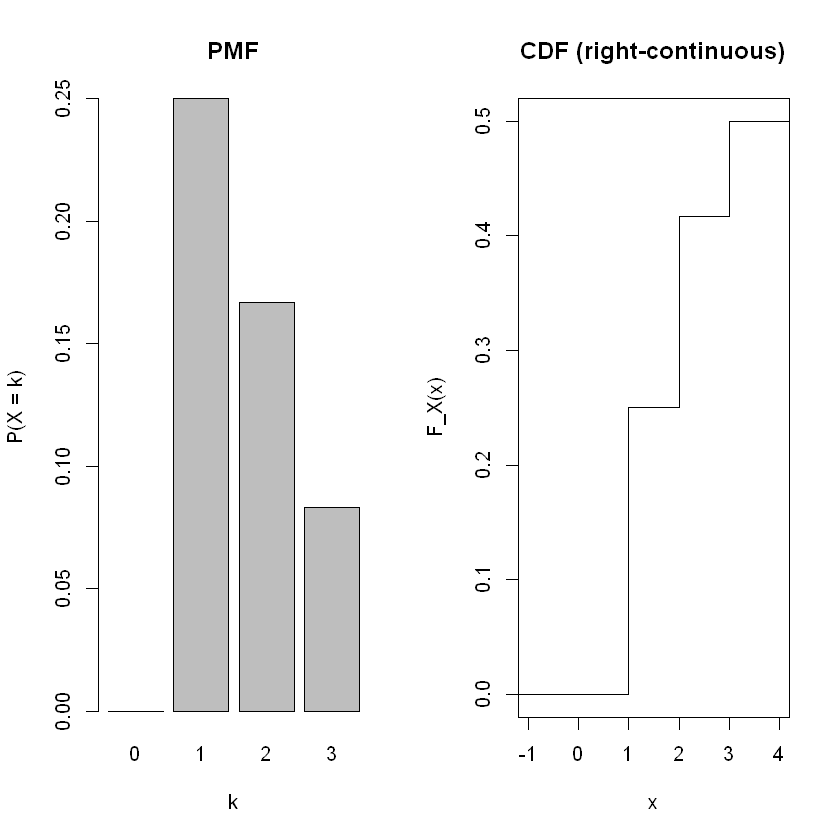

In [18]:
pmf_from_cdf <- function(support){
  # support: integer support points to evaluate (e.g., 0:3)
  # pmf(i) = F(i) - F(i-)
  # TODO: compute a data.frame with columns x and pmf
  pmf <- F_given(support) - F_given(support - 0.00000000001)
  data.frame(k = support, pmf = pmf)
  # data.frame(x=support, pmf=rep(pmf, length(support)))
}

pmf <- pmf_from_cdf(0:3)
pmf
sum(pmf_from_cdf(0:3)$pmf)
plot_pmf_cdf(pmf)

---
## Problem 8 — Expectation of a sum (indicator method) (10 pts)

Coupon–type model: With $N=200$ types, draw $n=300$ coupons **with replacement**. Let $D_n$ be the number of distinct types seen.

1. **(6 pts)** Represent $D_n=\sum_{j=1}^N I_j$ where $I_j$ indicates “type $j$ appears at least once,” and use linearity to derive $E[D_n]$.  
2. **(4 pts)** Monte Carlo: estimate $E[D_n]$ with $5\times10^4$ runs; report MC error and compare to the formula.

$I_j=\{1 \text{ if type }j\text{ appears at least once, }0 \text{ otherwise}\}$

$D_n=\sum_{j=1}^{N} I_j$

$E[D_n]=E\left[\sum_{j=1}^{N}I_j\right]=\sum_{j=1}^{N}E[I_j]$

$E[I_j]=P(I_j=1).$

We can find the probability that type $j$ is never observed, $1-\frac{1}{N}$

Because the $n$ draws are independent and with replacement,

$P(I_j=0)=\left(1-\frac{1}{N}\right)^n$

$P(I_j=1)=1-\left(1-\frac{1}{N}\right)^n$

$E[I_j]=1-\left(1-\frac{1}{N}\right)^n$

$E[D_n]=N\left[1-\left(1-\frac{1}{N}\right)^n\right]$

For $N=200$ and $n=300$,

$E[D_{300}]=200\left[1-\left(\frac{199}{200}\right)^{300}\right]\approx155.54156$

In [19]:
coupon_E <- function(N, n){
  # TODO: return the analytical expectation E[D_n] using the indicator method
  N * (1 - (1 - 1/N)^n)
}

coupon_E(200, 300)

[1] 155.5416

### Simulation

In [20]:
simulate_coupon <- function(N, n, R = 5e4){
  # TODO: simulate R experiments; in each, draw n labels from 1..N with replacement
  # and count the number of distinct types. Return list(mean_hat=..., se=...).
  D <- replicate(R, length(unique(sample(1:N, size = n, replace = TRUE))))
  mean_hat <- mean(D)
  se <- mc_se_mean(D)
  list(mean_hat = mean_hat, se = se)
}

simulate_coupon(200, 300, R=5e4)

$mean_hat
[1] 155.5474

$se
[1] 0.01996992

The simulated value is very close to the exact value and the standard error is small.

---
## ✅ Implementation & Style Requirements (graded across problems; 12 pts)

- **Reproducibility (3 pts):** fixed seed; no manual inputs; runs cleanly on “Restart & Run All”.  
- **Numerical care (3 pts):** stable probability computations; vectorize where sensible.  
- **Validation (3 pts):** test derived formulas via exact calculation or simulation.  
- **Clarity (3 pts):** each problem begins with a plan/derivation, followed by code and interpretation.

---
## 📦 Submission Checklist

- File: `lastname_firstname_ch4_random_variables.ipynb`  
- Kernel: **R**  
- All plots rendered inline; random processes seeded  
- Runtime ≤ ~2 minutes (reduce N if needed, but keep ≥ $10^5$ where specified)